# 01 EDA: VisDrone2019-VID
Logic lives in `hw2.analysis.eda`; each figure is saved to `images/eda_<name>.png` at 150 dpi. Raw data from `data/`, prepared frames from `data/prepared/`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from hw2.analysis import eda

pd.set_option("display.precision", 2, "display.max_rows", 80, "display.width", 160)
plt.rcParams["figure.dpi"] = 72
data = eda.load_labelled()
test = eda.load_test_images()

10:23:36 INFO hw2.analysis.eda: train: 24201 frames, 1105516 boxes, 63843 ignore regions


10:23:36 INFO hw2.analysis.eda: val: 2846 frames, 114132 boxes, 3995 ignore regions


## 1. Splits
Clips, frames and frames per clip; test from `test_images.csv`.

In [2]:
frames = {**{split: d.images for split, d in data.items()}, "test": test}
eda.split_table(frames)

,clips,frames,per_clip_min,per_clip_median,per_clip_max,resolutions
train,56,24201,58,383.5,1424,6
val,7,2846,184,349.0,978,5
test,48,3811,35,73.5,148,6


In [3]:
resolutions = eda.resolution_table(frames)
resolutions

train          val         test       
           clips frames clips frames clips frames
resolution                                       
3840x2160      0      0     1    978     0      0
2720x1530      2    473     1    349     0      0
2688x1512     11   3505     1    233     0      0
1920x1080      1    721     0      0    11    991
1904x1072      0      0     0      0     4    305
1904x1071     30  12895     2    459     0      0
1360x765       1    962     0      0     0      0
1360x764       0      0     0      0    18   1474
1344x756      11   5645     2    827     7    441
960x540        0      0     0      0     5    279
680x382        0      0     0      0     3    321

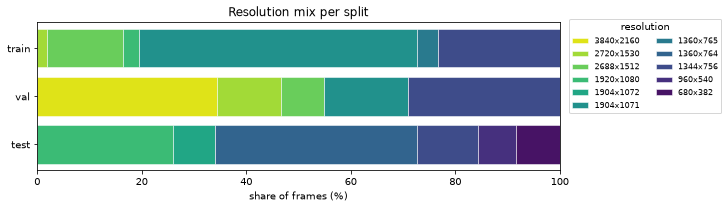

In [4]:
eda.save_figure(eda.plot_resolution_mix(resolutions), "resolutions")

Observation: TODO

## 2. Class distribution, train vs val

In [5]:
classes = eda.class_table(data)
classes

boxes        share_%       
           train    val   train    val
class                                 
person    328701  50312   29.73  44.08
bicycle    40255   6022    3.64   5.28
car       505301  31821   45.71  27.88
van        46940   6842    4.25   5.99
truck      30498   1359    2.76   1.19
tricycle   41349   5487    3.74   4.81
bus         9653    264    0.87   0.23
motor     102819  12025    9.30  10.54

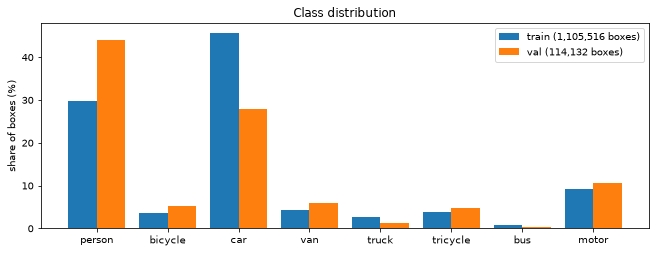

In [6]:
eda.save_figure(eda.plot_class_shares(classes), "classes")

Observation: TODO

## 3. Object sizes
Box side = sqrt(w*h) in original pixels; dashed lines are the COCO small and large edges (32, 96 px).

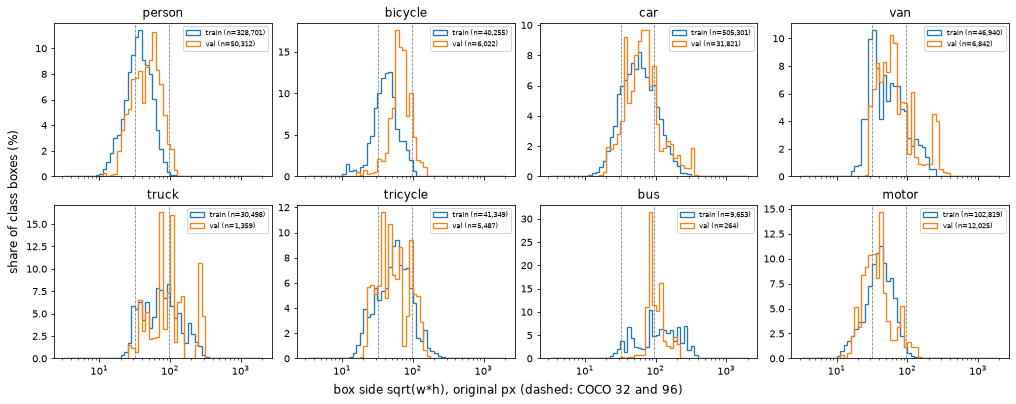

In [7]:
eda.save_figure(eda.plot_size_hist(data), "sizes_per_class")

Observation: TODO

In [8]:
eda.size_bucket_table(data)

split     train                  val              
size_%    small medium  large  small medium  large
class                                             
person    39.49  60.17   0.34  24.74  71.83   3.43
bicycle   24.41  74.11   1.48   2.86  85.62  11.52
car       16.32  64.52  19.15   9.39  70.74  19.87
van       21.40  62.74  15.85   5.76  71.41  22.83
truck      9.39  57.90  32.71   2.80  48.42  48.79
tricycle  21.03  66.13  12.84  18.52  59.05  22.43
bus        4.14  38.97  56.88   0.00  51.52  48.48
motor     30.37  68.22   1.42  40.37  55.14   4.49
all       24.91  63.50  11.59  19.20  69.53  11.27

In [9]:
eda.size_summary(data).round(2)

p10_px  median_px  p90_px  under_8px_%  under_16px_%  small_%  medium_%  large_%
split scale                                                                                           
train original         24.00      45.83  101.60         0.00          2.16    24.91     63.50    11.59
      long side 1280   16.08      30.39   66.31         0.60          9.84    54.17     42.81     3.01
val   original         26.08      52.39   99.35         0.00          0.33    19.20     69.53    11.27
      long side 1280   16.81      32.64   61.72         0.74          8.72    48.37     49.67     1.97

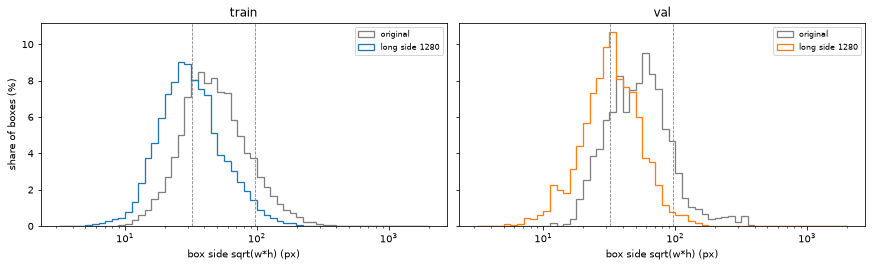

In [10]:
eda.save_figure(eda.plot_size_1280(data), "sizes_1280")

Observation: TODO

## 4. Objects per frame

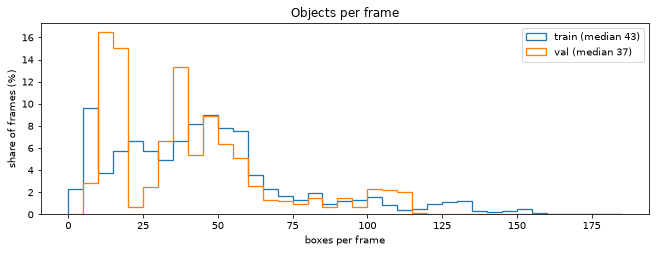

In [11]:
per_frame = eda.objects_per_frame(data)
eda.save_figure(eda.plot_objects_hist(per_frame), "objects_per_frame")

Observation: TODO

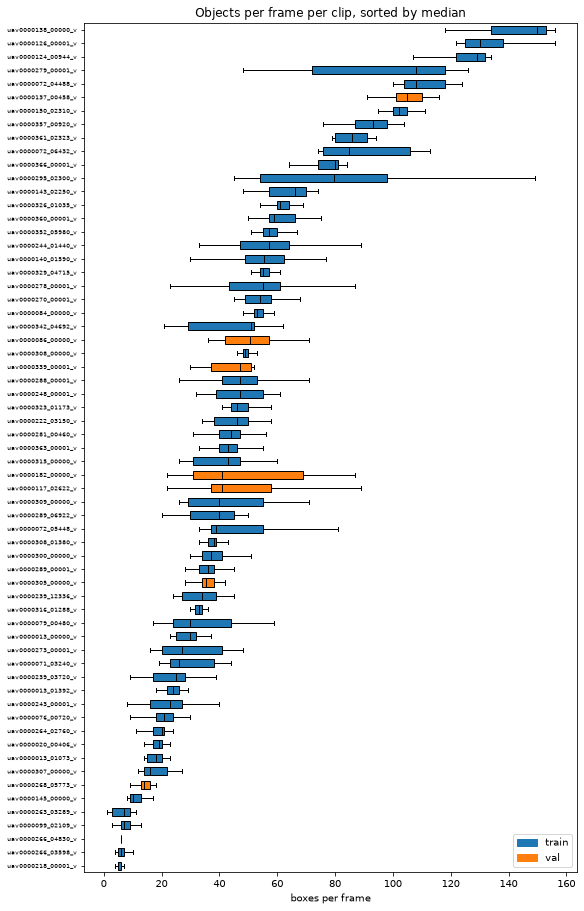

In [12]:
eda.save_figure(eda.plot_objects_per_clip(per_frame), "objects_per_clip")

Observation: TODO

In [13]:
eda.clip_table(data, per_frame)

,split,resolution,frames,mean_objects,median_side_px,top_classes
clip,,,,,,
uav0000138_00000_v,train,2688x1512,213,142.96,45.38,"car 41%, person 41%, bicycle 10%"
uav0000126_00001_v,train,2688x1512,412,132.22,48.37,"car 79%, person 12%, motor 4%"
uav0000124_00944_v,train,2688x1512,398,124.57,46.31,"car 67%, person 19%, bicycle 6%"
uav0000072_04488_v,train,1904x1071,85,110.38,45.83,"person 87%, car 4%, tricycle 3%"
uav0000150_02310_v,train,2688x1512,348,108.89,60.03,"motor 35%, person 25%, car 20%"
uav0000279_00001_v,train,1904x1071,547,95.35,33.36,"car 65%, person 22%, tricycle 4%"
uav0000357_00920_v,train,1904x1071,691,91.89,42.85,"person 40%, motor 25%, car 23%"
uav0000072_06432_v,train,1904x1071,97,89.95,42.33,"person 79%, car 9%, tricycle 8%"
uav0000361_02323_v,train,1904x1071,219,85.80,54.22,"car 39%, person 19%, van 19%"


## 5. Ignore regions
Share of the frame area covered by the union of ignore regions.

In [14]:
ignore = eda.ignore_shares(data)
eda.ignore_summary(ignore)

,frames_with_ignore_%,mean_area_%,p90_area_%,max_area_%,clips_with_ignore,clips,max_clip_mean_area_%
split,,,,,,,
train,74.75,2.38,5.79,38.00,50,56,24.43
val,50.39,1.60,6.54,10.35,5,7,7.90


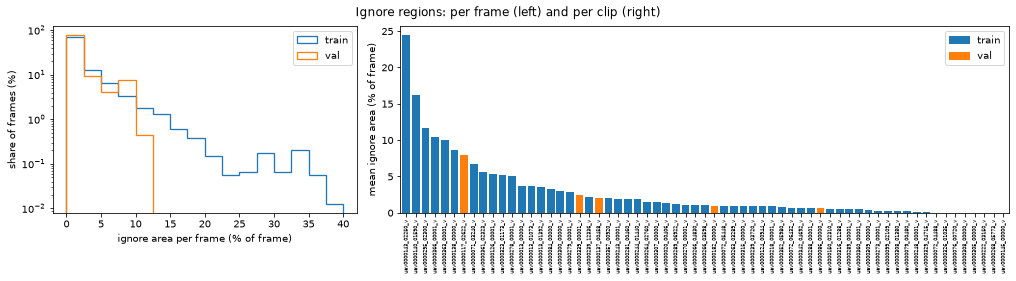

In [15]:
eda.save_figure(eda.plot_ignore(ignore), "ignore")

Observation: TODO

## 6. Temporal redundancy
Mean IoU of the same `track_id` between frames t and t+k (train, original pixels).

In [16]:
track = eda.track_iou(data["train"].objects)
track

,pairs,all,person,bicycle,car,van,truck,tricycle,bus,motor
k,,,,,,,,,,
1,1097628,0.85,0.80,0.81,0.89,0.90,0.91,0.86,0.93,0.82
2,1090077,0.75,0.67,0.69,0.80,0.83,0.85,0.77,0.87,0.70
5,1067598,0.56,0.45,0.48,0.64,0.67,0.70,0.57,0.74,0.49
10,1031089,0.41,0.29,0.33,0.48,0.53,0.55,0.40,0.59,0.34
20,961789,0.28,0.17,0.23,0.34,0.41,0.41,0.26,0.42,0.24


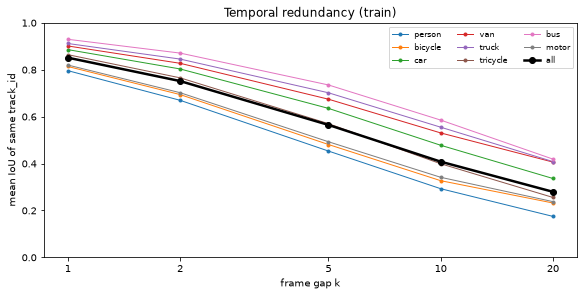

In [17]:
eda.save_figure(eda.plot_track_iou(track), "track_iou")

Observation: TODO

## 7. Conversion check
Seeded random prepared frames with ignore regions; boxes are read from the YOLO labels, white outlines are the raw ignore regions scaled to the prepared frame.

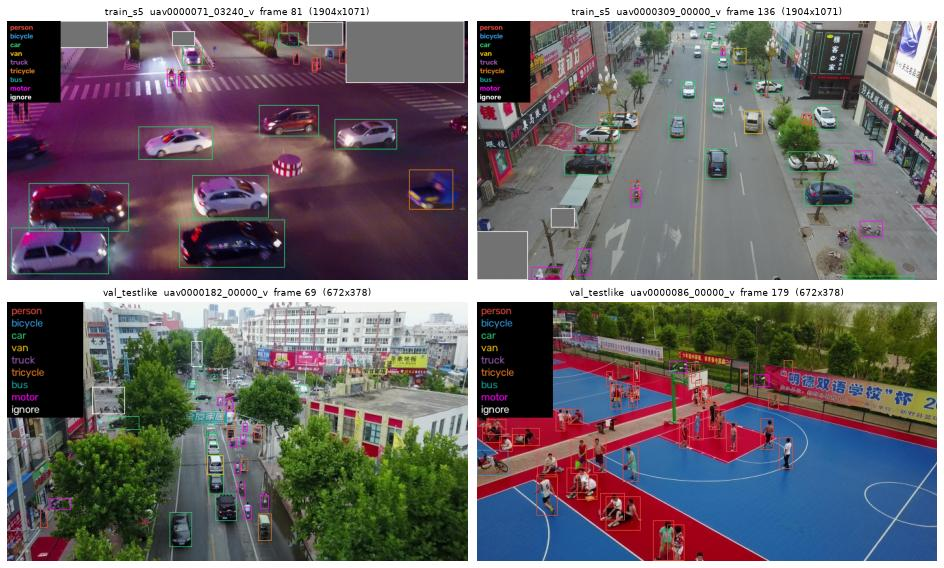

In [18]:
%config InlineBackend.figure_formats = ["jpeg"]  # photos, smaller notebook
overlays = eda.pick_overlay_frames()
eda.save_figure(eda.plot_overlays(overlays, data), "overlays")

Observation: TODO

## 8. Observation -> decision

| Observation | Decision |
|---|---|
|  |  |
|  |  |
|  |  |